# EDA of the Kaggle data (PaySim) — Data Analyst

**Goal (Module 2):** distributions, outliers, correlations, class imbalance, fraud rate by type and time,
fraud patterns; plus a leakage check and a proposal for the `step` split points.

- Data: `data/raw/PS_20174392719_1491204439457_log.csv` (PaySim, ~6.36M rows); read from `data/raw/kaggle dataset.zip` if the CSV is not extracted.
- Scope: Kaggle data only. EDA of the merged data (Kaggle + synthetic) is in notebook `eda_merged`.
- Can be run from any folder inside the repo. Charts are saved to `reports/figures/eda/kaggle/`.
- The first run converts the CSV to `data/raw/paysim.parquet` (a fallback while waiting for DE; once DE has the official parquet, point `PARQUET_PATH` to it).

In [1]:
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.csv as pv
import pyarrow.parquet as pq
import pyarrow.compute as pc
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())  # repo root
RAW_DIR = ROOT / "data" / "raw"
CSV_NAME = "PS_20174392719_1491204439457_log.csv"
CSV_PATH = RAW_DIR / CSV_NAME
ZIP_PATH = RAW_DIR / "kaggle dataset.zip"
PARQUET_PATH = RAW_DIR / "paysim.parquet"
FIG_DIR = ROOT / "reports" / "figures" / "eda" / "kaggle"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
FRAUD_COLOR, LEGIT_COLOR = "#d62728", "#1f77b4"

def savefig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## Convert CSV → parquet (first run only)

In [2]:
COLUMN_TYPES = {
    "step": pa.int16(), "type": pa.string(), "amount": pa.float64(),
    "nameOrig": pa.string(), "oldbalanceOrg": pa.float64(), "newbalanceOrig": pa.float64(),
    "nameDest": pa.string(), "oldbalanceDest": pa.float64(), "newbalanceDest": pa.float64(),
    "isFraud": pa.int8(), "isFlaggedFraud": pa.int8(),
}

def csv_to_parquet(f):
    reader = pv.open_csv(f, convert_options=pv.ConvertOptions(column_types=COLUMN_TYPES))
    with pq.ParquetWriter(PARQUET_PATH, reader.schema, compression="zstd") as writer:
        for batch in reader:
            writer.write_batch(batch)

if not PARQUET_PATH.exists():
    if CSV_PATH.exists():
        csv_to_parquet(CSV_PATH)
    else:
        with zipfile.ZipFile(ZIP_PATH) as zf, zf.open(CSV_NAME) as f:
            csv_to_parquet(f)
print(PARQUET_PATH.relative_to(ROOT), f"{PARQUET_PATH.stat().st_size / 1e6:,.0f} MB")

aw\paysim.parquet 258 MB


## Load and overview

Only numeric columns and `type` are loaded to save RAM; the two account-name columns are handled separately in the account-columns section.

In [3]:
NUM_COLS = ["step", "type", "amount", "oldbalanceOrg", "newbalanceOrig",
            "oldbalanceDest", "newbalanceDest", "isFraud", "isFlaggedFraud"]
df = pd.read_parquet(PARQUET_PATH, columns=NUM_COLS)
df["type"] = df["type"].astype("category")
print(df.shape)
df.info(memory_usage="deep")
df.head()

(6362620, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 9 columns):
 #   Column          Dtype   
---  ------          -----   
 0   step            int16   
 1   type            category
 2   amount          float64 
 3   oldbalanceOrg   float64 
 4   newbalanceOrig  float64 
 5   oldbalanceDest  float64 
 6   newbalanceDest  float64 
 7   isFraud         int8    
 8   isFlaggedFraud  int8    
dtypes: category(1), float64(5), int16(1), int8(2)
memory usage: 273.1 MB


,step,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,"9,839.6400","170,136.0000","160,296.3600",0.0000,0.0000,0,0
1,1,PAYMENT,"1,864.2800","21,249.0000","19,384.7200",0.0000,0.0000,0,0
2,1,TRANSFER,181.0000,181.0000,0.0000,0.0000,0.0000,1,0
3,1,CASH_OUT,181.0000,181.0000,0.0000,"21,182.0000",0.0000,1,0
4,1,PAYMENT,"11,668.1400","41,554.0000","29,885.8600",0.0000,0.0000,0,0


### Missing values, duplicates, invalid values

In [4]:
print("Missing values per column:")
print(df.isna().sum().to_string())

# Exact duplicates across all 11 columns (including account names): hash in batches to save RAM
pf = pq.ParquetFile(PARQUET_PATH)
hashes = np.concatenate([
    pd.util.hash_pandas_object(b.to_pandas(), index=False).to_numpy()
    for b in pf.iter_batches(batch_size=500_000)
])
print(f"\nExact duplicate rows: {len(hashes) - len(np.unique(hashes)):,}")
del hashes

print(f"amount < 0: {(df.amount < 0).sum():,}")
print(f"amount == 0: {(df.amount == 0).sum():,} (of which fraud: {((df.amount == 0) & (df.isFraud == 1)).sum():,})")
print(f"step: {df.step.min()} → {df.step.max()}, steps with data: {df.step.nunique()}")
df.drop(columns=["isFraud", "isFlaggedFraud"]).describe(percentiles=[.5, .9, .99, .999]).T

Missing values per column:
step              0
type              0
amount            0
oldbalanceOrg     0
newbalanceOrig    0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0



Exact duplicate rows: 0
amount < 0: 0
amount == 0: 16 (of which fraud: 16)
step: 1 → 743, steps with data: 743


,count,mean,std,min,50%,90%,99%,99.9%,max
step,"6,362,620.0000",243.3972,142.3320,1.0000,239.0000,399.0000,681.0000,710.0000,743.0000
amount,"6,362,620.0000","179,861.9035","603,858.2315",0.0000,"74,871.9400","365,423.3090","1,615,979.4716","8,956,797.6770","92,445,516.6400"
oldbalanceOrg,"6,362,620.0000","833,883.1041","2,888,242.6730",0.0000,"14,208.0000","1,822,508.2890","16,027,256.1337","26,825,930.2048","59,585,040.3700"
newbalanceOrig,"6,362,620.0000","855,113.6686","2,924,048.5030",0.0000,0.0000,"1,970,344.7930","16,176,160.5580","26,971,658.9303","49,585,040.3700"
oldbalanceDest,"6,362,620.0000","1,100,701.6665","3,399,180.1130",0.0000,"132,705.6650","2,914,266.6690","12,371,819.1548","34,392,786.7880","356,015,889.3500"
newbalanceDest,"6,362,620.0000","1,224,996.3982","3,674,128.9421",0.0000,"214,661.4400","3,194,869.6710","13,137,866.9410","39,531,571.9674","356,179,278.9200"


### Account columns (`nameOrig`, `nameDest`) and recipient features

Recipient features use only **earlier** transactions (the file is ordered by `step`), so they do not leak.
Within the same step, file row order is used.

In [5]:
tbl = pq.read_table(PARQUET_PATH, columns=["nameOrig", "nameDest"])
n_orig_unique = pc.count_distinct(tbl["nameOrig"]).as_py()
dest = tbl["nameDest"].combine_chunks()
dest_code = dest.dictionary_encode().indices.to_numpy()
dest_is_merchant = pc.starts_with(dest, "M").to_numpy(zero_copy_only=False)
n_dest_unique = int(dest_code.max()) + 1
del tbl, dest

print(f"Distinct nameOrig: {n_orig_unique:,} / {len(df):,} rows ({n_orig_unique / len(df):.2%})")
print(f"Distinct nameDest: {n_dest_unique:,}")

dest_group = pd.Series(dest_code, index=df.index)
df["dest_prior_count"] = dest_group.groupby(dest_code).cumcount().astype("int32")
df["dest_steps_since_last"] = (df.step - df.step.groupby(dest_code).shift(1)).astype("float32")
df["is_new_dest"] = (df.dest_prior_count == 0).astype("int8")
df["dest_is_merchant"] = dest_is_merchant
df["hour"] = (df.step % 24).astype("int8")  # assumes step 1 = hour 1 of the simulation
del dest_code, dest_is_merchant, dest_group

pd.crosstab(df.type, df.dest_is_merchant, margins=True).rename(columns={False: "Customer C...", True: "Merchant M..."})

Distinct nameOrig: 6,353,307 / 6,362,620 rows (99.85%)
Distinct nameDest: 2,722,362


dest_is_merchant,Customer C...,Merchant M...,All
type,,,
CASH_IN,1399284,0,1399284
CASH_OUT,2237500,0,2237500
DEBIT,41432,0,41432
PAYMENT,0,2151495,2151495
TRANSFER,532909,0,532909
All,4211125,2151495,6362620


## Class imbalance and fraud by transaction type

In [6]:
n_fraud = int(df.isFraud.sum())
print(f"Fraud: {n_fraud:,} / {len(df):,} = {n_fraud / len(df):.4%}  (legit:fraud ≈ {(len(df) - n_fraud) / n_fraud:,.0f}:1)")

by_type = (df.groupby("type", observed=True)
             .agg(n=("isFraud", "size"), n_fraud=("isFraud", "sum"), fraud_rate=("isFraud", "mean"))
             .sort_values("n", ascending=False))
by_type["share_of_rows"] = by_type.n / by_type.n.sum()
by_type

Fraud: 8,213 / 6,362,620 = 0.1291%  (legit:fraud ≈ 774:1)


,n,n_fraud,fraud_rate,share_of_rows
type,,,,
CASH_OUT,2237500,4116,0.0018,0.3517
PAYMENT,2151495,0,0.0000,0.3381
CASH_IN,1399284,0,0.0000,0.2199
TRANSFER,532909,4097,0.0077,0.0838
DEBIT,41432,0,0.0000,0.0065


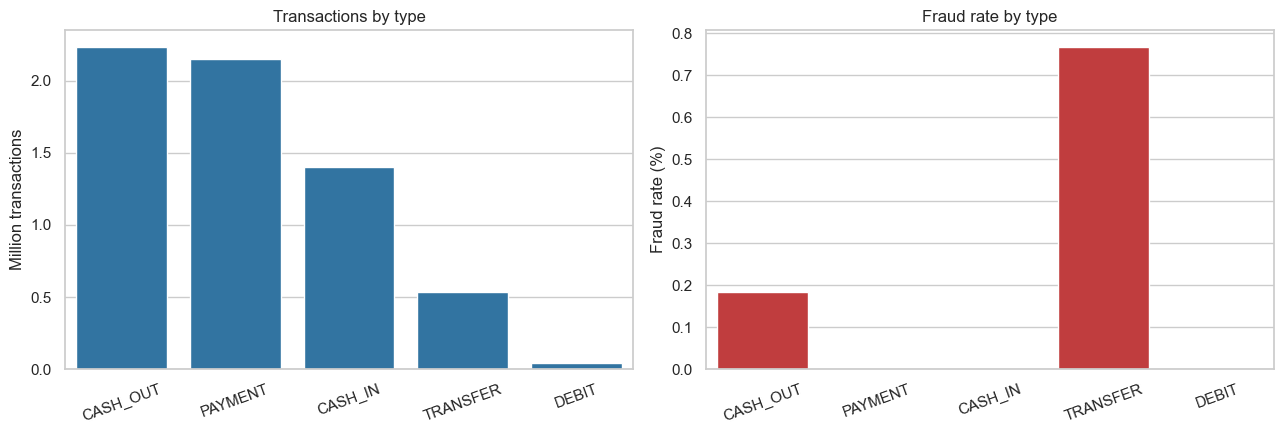

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(x=by_type.index.astype(str), y=by_type.n / 1e6, color=LEGIT_COLOR, ax=axes[0])
axes[0].set(title="Transactions by type", xlabel="", ylabel="Million transactions")
sns.barplot(x=by_type.index.astype(str), y=by_type.fraud_rate * 100, color=FRAUD_COLOR, ax=axes[1])
axes[1].set(title="Fraud rate by type", xlabel="", ylabel="Fraud rate (%)")
for ax in axes:
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); savefig("type_volume_fraud_rate"); plt.show()

Fraud occurs only in `TRANSFER` and `CASH_OUT`. The following sections (amount, balances, correlation, AUC) use
this subset (`tc`), because comparing against PAYMENT/DEBIT/CASH_IN would inflate every signal.

In [8]:
tc = df[df.type.isin(["TRANSFER", "CASH_OUT"])].copy()
tc["type"] = tc["type"].cat.remove_unused_categories()
print(f"TRANSFER + CASH_OUT: {len(tc):,} rows, fraud rate {tc.isFraud.mean():.3%}")

TRANSFER + CASH_OUT: 2,770,409 rows, fraud rate 0.296%


## Amount: distribution, fraud rate by amount, outliers

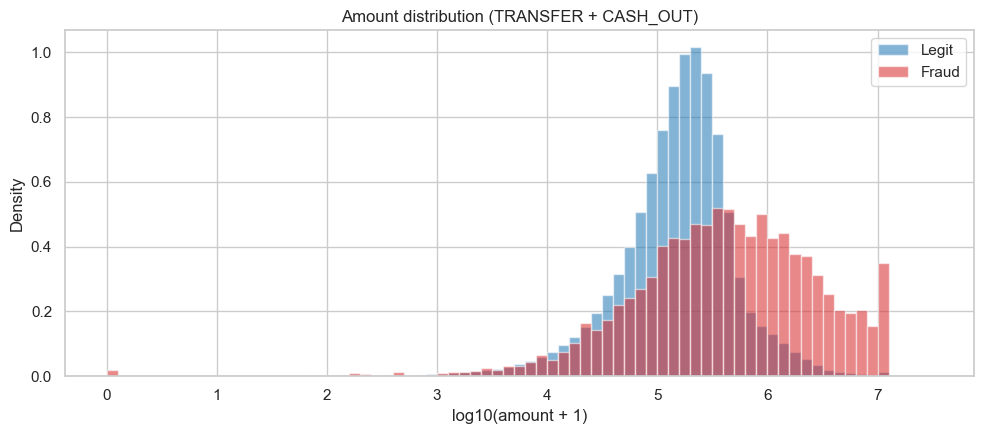

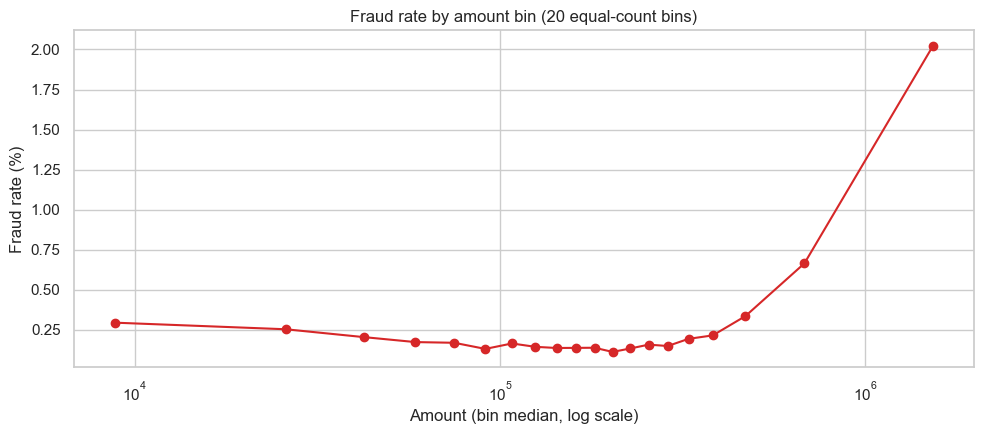

,median_amount,n,fraud_rate
amount_bin,,,
"(-0.001, 17383.422]","8,802.5100",138521,0.0029
"(17383.422, 34162.534]","25,861.2650",138520,0.0025
"(34162.534, 50536.968]","42,373.2300",138521,0.0020
"(50536.968, 66797.146]","58,650.0100",138520,0.0017
"(66797.146, 82973.54]","74,881.3200",138521,0.0017
"(82973.54, 99390.778]","91,148.9300",138520,0.0013
"(99390.778, 116304.206]","107,771.0750",138520,0.0016
"(116304.206, 133738.014]","124,950.8500",138521,0.0014
"(133738.014, 151943.994]","142,753.2950",138520,0.0014


In [9]:
fig, ax = plt.subplots(figsize=(10, 4.5))
bins = np.linspace(0, 7.5, 76)
for lbl, color, name in [(0, LEGIT_COLOR, "Legit"), (1, FRAUD_COLOR, "Fraud")]:
    ax.hist(np.log10(tc.loc[tc.isFraud == lbl, "amount"] + 1), bins=bins, density=True,
            alpha=.55, color=color, label=name)
ax.set(title="Amount distribution (TRANSFER + CASH_OUT)", xlabel="log10(amount + 1)", ylabel="Density")
ax.legend(); plt.tight_layout(); savefig("amount_distribution"); plt.show()

tc["amount_bin"] = pd.qcut(tc.amount, 20, duplicates="drop")
amt = tc.groupby("amount_bin", observed=True).agg(median_amount=("amount", "median"),
                                                  n=("isFraud", "size"), fraud_rate=("isFraud", "mean"))
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(amt.median_amount, amt.fraud_rate * 100, marker="o", color=FRAUD_COLOR)
ax.set(xscale="log", title="Fraud rate by amount bin (20 equal-count bins)",
       xlabel="Amount (bin median, log scale)", ylabel="Fraud rate (%)")
plt.tight_layout(); savefig("fraud_rate_by_amount"); plt.show()
amt

In [10]:
q1, q3 = np.log10(tc.amount + 1).quantile([.25, .75])
upper = 10 ** (q3 + 1.5 * (q3 - q1)) - 1
out = tc.amount > upper
print(f"Outlier threshold (IQR on log amount): {upper:,.0f}")
print(f"Outliers: {out.sum():,} rows ({out.mean():.2%}), fraud rate among outliers: {tc.loc[out, 'isFraud'].mean():.2%}")
print(f"Max amount: {tc.amount.max():,.0f}")
print(f"Fraud with amount exactly 10,000,000: {((tc.amount == 1e7) & (tc.isFraud == 1)).sum():,} / {int(tc.isFraud.sum()):,}")
print(f"Legit with amount exactly 10,000,000: {((tc.amount == 1e7) & (tc.isFraud == 0)).sum():,}")
print(f"Max fraud amount: {tc.loc[tc.isFraud == 1, 'amount'].max():,.0f}")
print(f"Transactions > 10,000,000: {(tc.amount > 1e7).sum():,} rows, fraud: {int(tc.loc[tc.amount > 1e7, 'isFraud'].sum())}")

flag_rule = (df.type == "TRANSFER") & (df.amount > 200_000)
print(f"\nisFlaggedFraud = 1: {int(df.isFlaggedFraud.sum())} rows, of which fraud: {int(df.loc[df.isFlaggedFraud == 1, 'isFraud'].sum())}")
print(f"TRANSFER > 200k: {flag_rule.sum():,} rows → the isFlaggedFraud rule almost never fires")

Outlier threshold (IQR on log amount): 2,181,189
Outliers: 38,431 rows (1.39%), fraud rate among outliers: 4.02%
Max amount: 92,445,517
Fraud with amount exactly 10,000,000: 287 / 8,213
Legit with amount exactly 10,000,000: 2,920
Max fraud amount: 10,000,000
Transactions > 10,000,000: 2,443 rows, fraud: 0

isFlaggedFraud = 1: 16 rows, of which fraud: 16
TRANSFER > 200k: 409,110 rows → the isFlaggedFraud rule almost never fires


## Time: by step and by hour of day

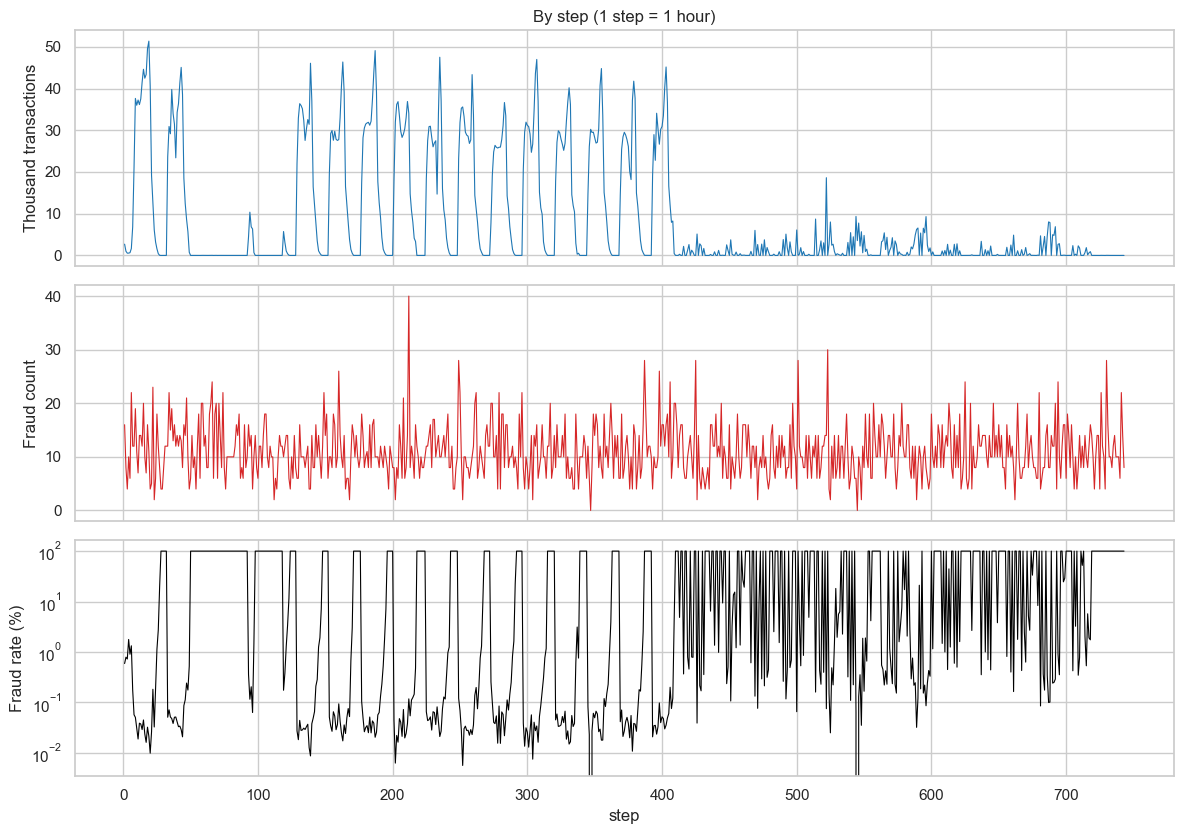

Step ≥ 400: 9.5% of rows but 45.7% of fraud
Fraud rate step < 400: 0.078%  |  step ≥ 400: 0.619%


In [11]:
by_step = df.groupby("step").agg(n=("isFraud", "size"), n_fraud=("isFraud", "sum"))
by_step["fraud_rate"] = by_step.n_fraud / by_step.n

fig, axes = plt.subplots(3, 1, figsize=(12, 8.5), sharex=True)
axes[0].plot(by_step.index, by_step.n / 1e3, color=LEGIT_COLOR, lw=.8)
axes[0].set(ylabel="Thousand transactions", title="By step (1 step = 1 hour)")
axes[1].plot(by_step.index, by_step.n_fraud, color=FRAUD_COLOR, lw=.8)
axes[1].set(ylabel="Fraud count")
axes[2].plot(by_step.index, by_step.fraud_rate * 100, color="black", lw=.8)
axes[2].set(ylabel="Fraud rate (%)", yscale="log", xlabel="step")
plt.tight_layout(); savefig("volume_fraud_by_step"); plt.show()

late = df.step >= 400
print(f"Step ≥ 400: {late.mean():.1%} of rows but {df.loc[late, 'isFraud'].sum() / n_fraud:.1%} of fraud")
print(f"Fraud rate step < 400: {df.loc[~late, 'isFraud'].mean():.3%}  |  step ≥ 400: {df.loc[late, 'isFraud'].mean():.3%}")

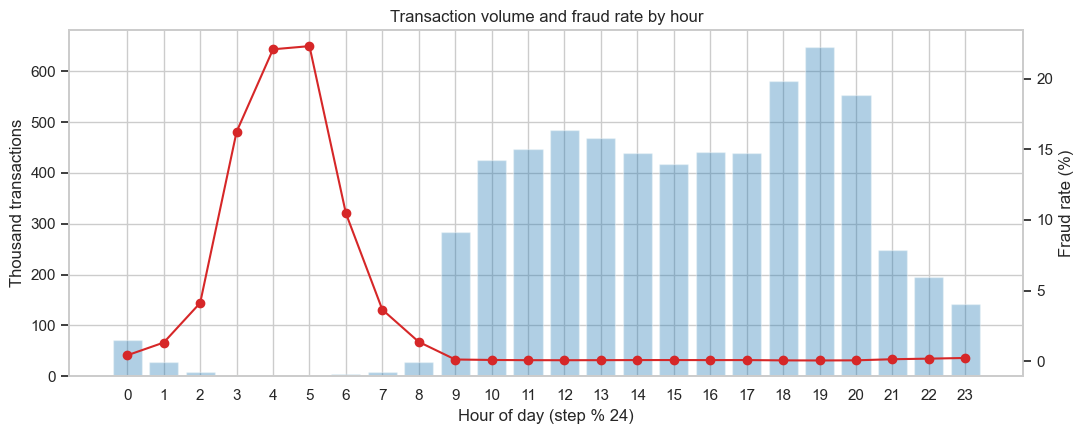

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
n,"71,587.0000","27,111.0000","9,018.0000","2,007.0000","1,241.0000","1,641.0000","3,420.0000","8,988.0000","26,915.0000","283,518.0000",...,"439,653.0000","416,686.0000","441,612.0000","439,941.0000","580,509.0000","647,814.0000","553,728.0000","247,806.0000","194,555.0000","141,257.0000"
fraud_rate,0.0042,0.0132,0.0413,0.1624,0.2208,0.2230,0.1047,0.0365,0.0137,0.0012,...,0.0008,0.0008,0.0008,0.0008,0.0006,0.0005,0.0006,0.0014,0.0018,0.0023


In [12]:
by_hour = df.groupby("hour").agg(n=("isFraud", "size"), fraud_rate=("isFraud", "mean"))
fig, ax1 = plt.subplots(figsize=(11, 4.5))
ax1.bar(by_hour.index, by_hour.n / 1e3, color=LEGIT_COLOR, alpha=.35, label="Transactions")
ax1.set(xlabel="Hour of day (step % 24)", ylabel="Thousand transactions", xticks=range(24))
ax2 = ax1.twinx()
ax2.plot(by_hour.index, by_hour.fraud_rate * 100, color=FRAUD_COLOR, marker="o", label="Fraud rate")
ax2.set(ylabel="Fraud rate (%)"); ax2.grid(False)
ax1.set_title("Transaction volume and fraud rate by hour")
plt.tight_layout(); savefig("volume_fraud_by_hour"); plt.show()
by_hour.T

## Balance columns: a near-perfect label leak

The original PaySim description states that fraudulent transactions are cancelled, so the 4 balance columns
should not be used for fraud detection. The table below shows why.

In [13]:
flags = pd.DataFrame({
    "oldbalanceOrg == amount (account drained)": tc.oldbalanceOrg == tc.amount,
    "oldbalanceOrg == 0": tc.oldbalanceOrg == 0,
    "newbalanceOrig == 0": tc.newbalanceOrig == 0,
    "old - amount ≠ new (sender)": ~np.isclose(tc.oldbalanceOrg - tc.amount, tc.newbalanceOrig, atol=0.01),
    "oldbalanceDest == 0 and newbalanceDest == 0": (tc.oldbalanceDest == 0) & (tc.newbalanceDest == 0),
})
leak = flags.groupby(tc.isFraud).mean().T * 100
leak.columns = ["Legit (%)", "Fraud (%)"]
leak

,Legit (%),Fraud (%)
oldbalanceOrg == amount (account drained),0.0000,97.8205
oldbalanceOrg == 0,47.3732,0.4992
newbalanceOrig == 0,90.0951,98.0519
old - amount ≠ new (sender),90.0952,0.5479
oldbalanceDest == 0 and newbalanceDest == 0,0.0618,49.6286


## Recipients (`nameDest`)

In [14]:
dest_tbl = pd.DataFrame({
    "First-time recipient (%)": tc.groupby("isFraud").is_new_dest.mean() * 100,
    "Prior receives (mean)": tc.groupby("isFraud").dest_prior_count.mean(),
    "Recipient had a transaction within 24 steps (%)":
        tc.assign(r=tc.dest_steps_since_last <= 24).groupby("isFraud").r.mean() * 100,
}).T
dest_tbl.columns = ["Legit", "Fraud"]
print(f"Fraud sent to merchants: {int(df.loc[df.dest_is_merchant, 'isFraud'].sum())}")
dest_tbl

Fraud sent to merchants: 0


,Legit,Fraud
First-time recipient (%),13.9849,62.9977
Prior receives (mean),7.7352,2.7013
Recipient had a transaction within 24 steps (%),57.8683,12.8942


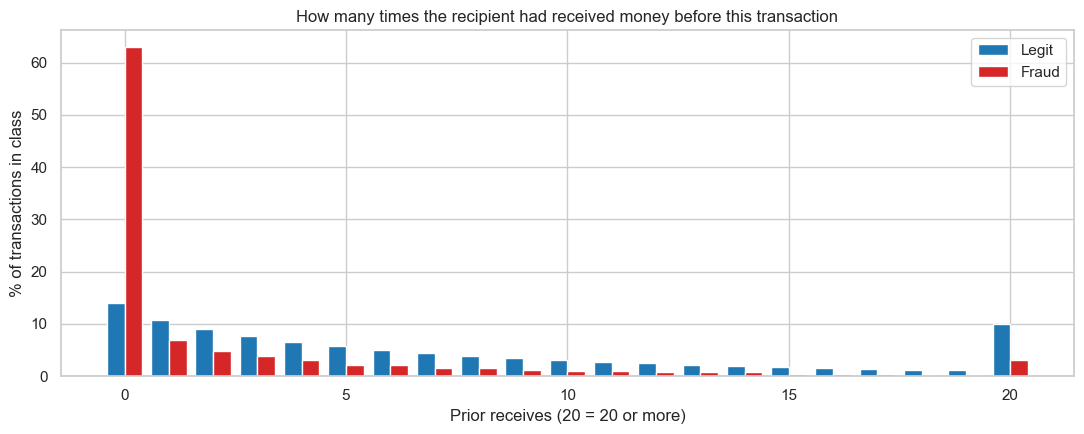

In [15]:
cap = 20
dist = (tc.assign(prior=tc.dest_prior_count.clip(upper=cap))
          .groupby(["isFraud", "prior"]).size()
          .groupby(level=0).transform(lambda s: s / s.sum()).unstack(0) * 100)
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(dist.index - .2, dist[0], width=.4, color=LEGIT_COLOR, label="Legit")
ax.bar(dist.index + .2, dist[1], width=.4, color=FRAUD_COLOR, label="Fraud")
ax.set(title="How many times the recipient had received money before this transaction",
       xlabel=f"Prior receives ({cap} = {cap} or more)", ylabel="% of transactions in class")
ax.legend(); plt.tight_layout(); savefig("recipient_prior_count"); plt.show()

## Correlation and single-feature discriminative power

Spearman on `tc`. Single-feature AUC = how well fraud and legit separate using that feature alone (0.5 = useless, 1 = perfect).
The same check will be applied to the synthetic fields in the merged-data notebook: anything above 0.85–0.9 is suspicious.

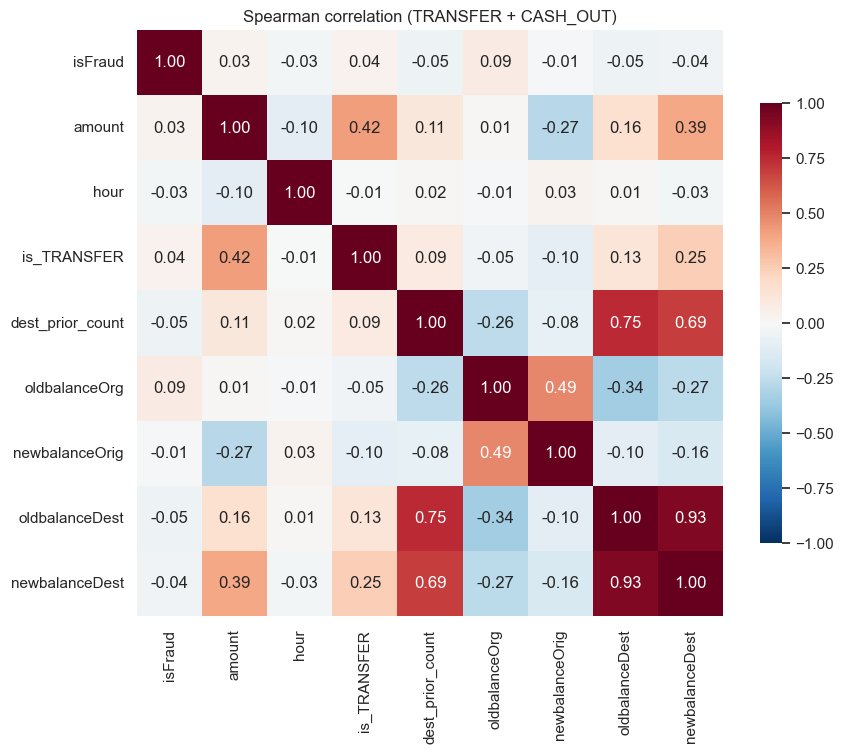

In [16]:
tc["is_TRANSFER"] = (tc.type == "TRANSFER").astype("int8")
corr_cols = ["isFraud", "amount", "hour", "is_TRANSFER", "dest_prior_count",
             "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest"]
corr = tc[corr_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, ax=ax,
            cbar_kws={"shrink": .75})
ax.set_title("Spearman correlation (TRANSFER + CASH_OUT)")
plt.tight_layout(); savefig("spearman_correlation"); plt.show()

In [17]:
candidates = {
    "amount": tc.amount,
    "hour": tc.hour,
    "is_TRANSFER": tc.is_TRANSFER,
    "is_new_dest": tc.is_new_dest,
    "dest_prior_count": tc.dest_prior_count,
    "dest_steps_since_last (never = 9999)": tc.dest_steps_since_last.fillna(9999),
    "[balance] oldbalanceOrg": tc.oldbalanceOrg,
    "[balance] newbalanceOrig": tc.newbalanceOrig,
    "[balance] oldbalanceDest": tc.oldbalanceDest,
    "[balance] newbalanceDest": tc.newbalanceDest,
    "[balance] account drained (oldbalanceOrg == amount)": (tc.oldbalanceOrg == tc.amount).astype("int8"),
    "[balance] both recipient balances = 0": ((tc.oldbalanceDest == 0) & (tc.newbalanceDest == 0)).astype("int8"),
}
rows = []
for name, s in candidates.items():
    a = roc_auc_score(tc.isFraud, s)
    rows.append({"feature": name, "AUC": max(a, 1 - a), "direction": "higher → fraud" if a >= .5 else "lower → fraud"})
auc_tbl = pd.DataFrame(rows).sort_values("AUC", ascending=False).reset_index(drop=True)
auc_tbl

,feature,AUC,direction
0,[balance] account drained (oldbalanceOrg == am...,0.9891,higher → fraud
1,[balance] oldbalanceOrg,0.9277,higher → fraud
2,dest_steps_since_last (never = 9999),0.8167,higher → fraud
3,[balance] oldbalanceDest,0.7859,lower → fraud
4,dest_prior_count,0.7685,lower → fraud
5,[balance] both recipient balances = 0,0.7478,higher → fraud
6,is_new_dest,0.7451,higher → fraud
7,[balance] newbalanceDest,0.7267,lower → fraud
8,amount,0.6834,higher → fraud
9,hour,0.6586,lower → fraud


## Proposed `step` split points (draft)

Time-based split: train → val → test → stream. Option A cuts at cumulative row share 60 / 15 / 15 / 10.
The final version goes to DE before Nov 25, after looking at the merged data.

In [18]:
cum = by_step[["n", "n_fraud"]].cumsum() / by_step[["n", "n_fraud"]].sum()

def cut_at(share):
    return int(cum.index[np.searchsorted(cum.n.to_numpy(), share)])

c1, c2, c3 = cut_at(.60), cut_at(.75), cut_at(.90)
split = pd.cut(df.step, [0, c1, c2, c3, df.step.max()], labels=["train", "val", "test", "stream"])
split_tbl = df.groupby(split, observed=True).agg(
    step_from=("step", "min"), step_to=("step", "max"),
    n=("isFraud", "size"), n_fraud=("isFraud", "sum"), fraud_rate=("isFraud", "mean"))
split_tbl["share_rows"] = split_tbl.n / len(df)
split_tbl["share_fraud"] = split_tbl.n_fraud / n_fraud
print(f"Option A: train ≤ {c1} < val ≤ {c2} < test ≤ {c3} < stream")
split_tbl

Option A: train ≤ 281 < val ≤ 335 < test ≤ 399 < stream


,step_from,step_to,n,n_fraud,fraud_rate,share_rows,share_fraud
step,,,,,,,
train,1,281,3820599,3193,0.0008,0.6005,0.3888
val,282,335,961244,556,0.0006,0.1511,0.0677
test,336,399,974277,712,0.0007,0.1531,0.0867
stream,400,743,606500,3752,0.0062,0.0953,0.4568


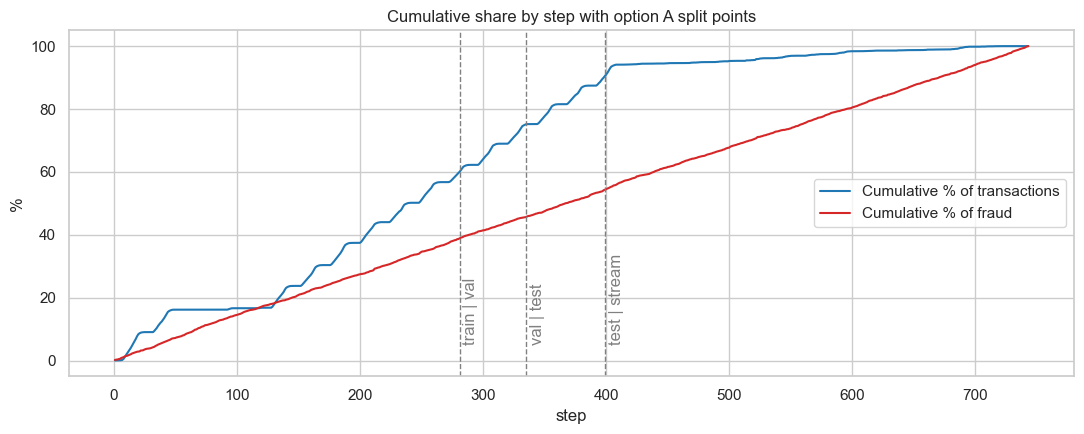

In [19]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(cum.index, cum.n * 100, color=LEGIT_COLOR, label="Cumulative % of transactions")
ax.plot(cum.index, cum.n_fraud * 100, color=FRAUD_COLOR, label="Cumulative % of fraud")
for c, lbl in [(c1, "train | val"), (c2, "val | test"), (c3, "test | stream")]:
    ax.axvline(c, color="gray", ls="--", lw=1)
    ax.text(c + 3, 5, lbl, rotation=90, color="gray", va="bottom")
ax.set(title="Cumulative share by step with option A split points", xlabel="step", ylabel="%")
ax.legend(loc="center right"); plt.tight_layout(); savefig("split_cumulative_share"); plt.show()

**Option B:** cut at cumulative **fraud** share 60 / 15 / 15 / 10, so val and test get enough fraud
and the stream does not hold almost half of all fraud.

In [20]:
def cut_at_fraud(share):
    return int(cum.index[np.searchsorted(cum.n_fraud.to_numpy(), share)])

b1, b2, b3 = cut_at_fraud(.60), cut_at_fraud(.75), cut_at_fraud(.90)
split_b = pd.cut(df.step, [0, b1, b2, b3, df.step.max()], labels=["train", "val", "test", "stream"])
split_b_tbl = df.groupby(split_b, observed=True).agg(
    step_from=("step", "min"), step_to=("step", "max"),
    n=("isFraud", "size"), n_fraud=("isFraud", "sum"), fraud_rate=("isFraud", "mean"))
split_b_tbl["share_rows"] = split_b_tbl.n / len(df)
split_b_tbl["share_fraud"] = split_b_tbl.n_fraud / n_fraud
print(f"Option B: train ≤ {b1} < val ≤ {b2} < test ≤ {b3} < stream")
split_b_tbl

Option B: train ≤ 439 < val ≤ 558 < test ≤ 671 < stream


,step_from,step_to,n,n_fraud,fraud_rate,share_rows,share_fraud
step,,,,,,,
train,1,439,6009593,4931,0.0008,0.9445,0.6004
val,440,558,159102,1234,0.0078,0.0250,0.1502
test,559,671,127323,1240,0.0097,0.0200,0.1510
stream,672,743,66602,808,0.0121,0.0105,0.0984


## Insight summary

**Data quality**
- 6,362,620 rows × 11 columns, no missing values, no duplicate rows, no negative amounts.
- 16 transactions have `amount = 0`, all fraud → DE decides whether to keep or drop them during cleaning.

**Class imbalance**
- 8,213 fraud = **0.129%** (≈ 774 legit : 1 fraud).
- Fraud occurs only in `TRANSFER` (0.77%) and `CASH_OUT` (0.18%); within these two types the fraud rate is 0.296%.
- `PAYMENT`, `CASH_IN` and `DEBIT` have no fraud at all; merchant recipients (`M...`) never receive fraud.

**Amount**
- Fraud rate rises with amount: about 0.15% in the middle bins → **2.0%** in the top 5% of transactions.
- Fraud is capped at **10,000,000** (287 fraud rows at exactly this value); all 2,443 transactions above 10M are legit.
  This is a PaySim simulation artifact; a model could wrongly learn "above 10M = safe" → note under limitations.
- IQR outliers (log amount): 1.39% of rows with a 4.0% fraud rate → outliers should not be removed.

**Time**
- By hour: fraud rate is **16–22%** at 3–6 AM vs below 0.1% during the day, because there is very little legit
  activity at night while fraud is spread evenly. Feed hour to the model as sin/cos or a night flag, not linearly.
- By step: from step 400 on there are only 9.5% of transactions but **45.7%** of fraud;
  the fraud rate rises from 0.078% to 0.619% (~8×).

**Leakage in the balance columns**
- "Account drained" (`oldbalanceOrg == amount`): 97.8% of fraud vs 0.0% of legit, single-feature AUC **0.989**.
- Both recipient balances zero: 49.6% of fraud vs 0.06% of legit.
- → Do not use the 4 balance columns (or features derived from them) in the main model; optionally run a separate comparison model.

**Accounts**
- `nameOrig` is unique in 99.85% of rows → sender velocity cannot be computed → a synthetic `customer_id` is needed.
- Recipients: **63%** of fraud goes to a first-time recipient vs 14% of legit.
  Single-feature AUC: `dest_steps_since_last` 0.82, `is_new_dest` 0.75. Real signal, using past data only.

**Existing baseline**
- `isFlaggedFraud` fires 16 times, all correct, but misses the other 8,197 fraud cases → a very weak baseline.

**Proposed split (to DE)**
- Option A (row share 60/15/15/10): train 1–281, val 282–335, test 336–399, stream 400–743.
  Val has 556 fraud, test 712; the stream holds 45.7% of all fraud at a 0.62% fraud rate.
- Option B (fraud share): val/test shrink to 2–2.5% of rows with a fraud rate ~10× train → val/test no longer resemble train.
- **Choose A**: train/val/test all come from the normal-volume period; the final period becomes the stream and
  naturally carries a fraud-rate shift → usable for monitoring. Tell Eval and MLOps:
  precision on the stream will differ sharply from val; that is real data drift, not a model bug.